In [50]:
## initialising file directory, defining data-sets

import os

output_folder = "/home/jacob-manning/attys_data/exported graphs"

recording_name = "Oliver eyes open2"

# Create recording-specific folder
save_folder = os.path.join(output_folder, recording_name)

os.makedirs(save_folder, exist_ok=True)

In [56]:
## Loading files and assigning values and variables

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch, welch, spectrogram
 
#1. Load the TSV file (replace with your file name)
filename = "/home/jacob-manning/attys_data/Attys Recordings/Oliver Tests 05.11/attysecg-2026-04-11-14-33-04.tsv"
df = pd.read_csv(filename, sep='\t', header=None)

t_start = 20 
t_end = 40  


# Slice the dataframe to only include rows within this time range
df_snippet = df[(df[0] >= t_start) & (df[0] <= t_end)]

time = df[0]
ecg_raw = df[3]  # Channel 1
eeg_raw = df[2]  # Channel 2
HRV = df[1]


# 3. Optional: Filter EEG in Python (0.5 - 35 Hz Bandpass + 50Hz Notch)
def filter_eeg(data, fs=250):
    b_notch, a_notch = iirnotch(w0=50.0, Q=30.0, fs=fs)   # 50 Hz Powerline Notch Filter (use 60.0 for US)
    data_notch = filtfilt(b_notch, a_notch, data)
    
    # 0.5 - 30 Hz Bandpass Filter for brainwaves
    b_band, a_band = butter(N=2, Wn=[0.5, 30.0], btype='bandpass', fs=fs)
    data_filtered = filtfilt(b_band, a_band, data_notch)
    return data_filtered
    

eeg_filtered = filter_eeg(eeg_raw) * 1e6  # Convert V to uV
ecg_mv = ecg_raw * 1e3                   # Convert V to mV

fs = 250  # Sampling rate in Hz
freqs, psd = welch(eeg_filtered, fs=fs, nperseg=fs*2)  # Power Spectral Density using Welch


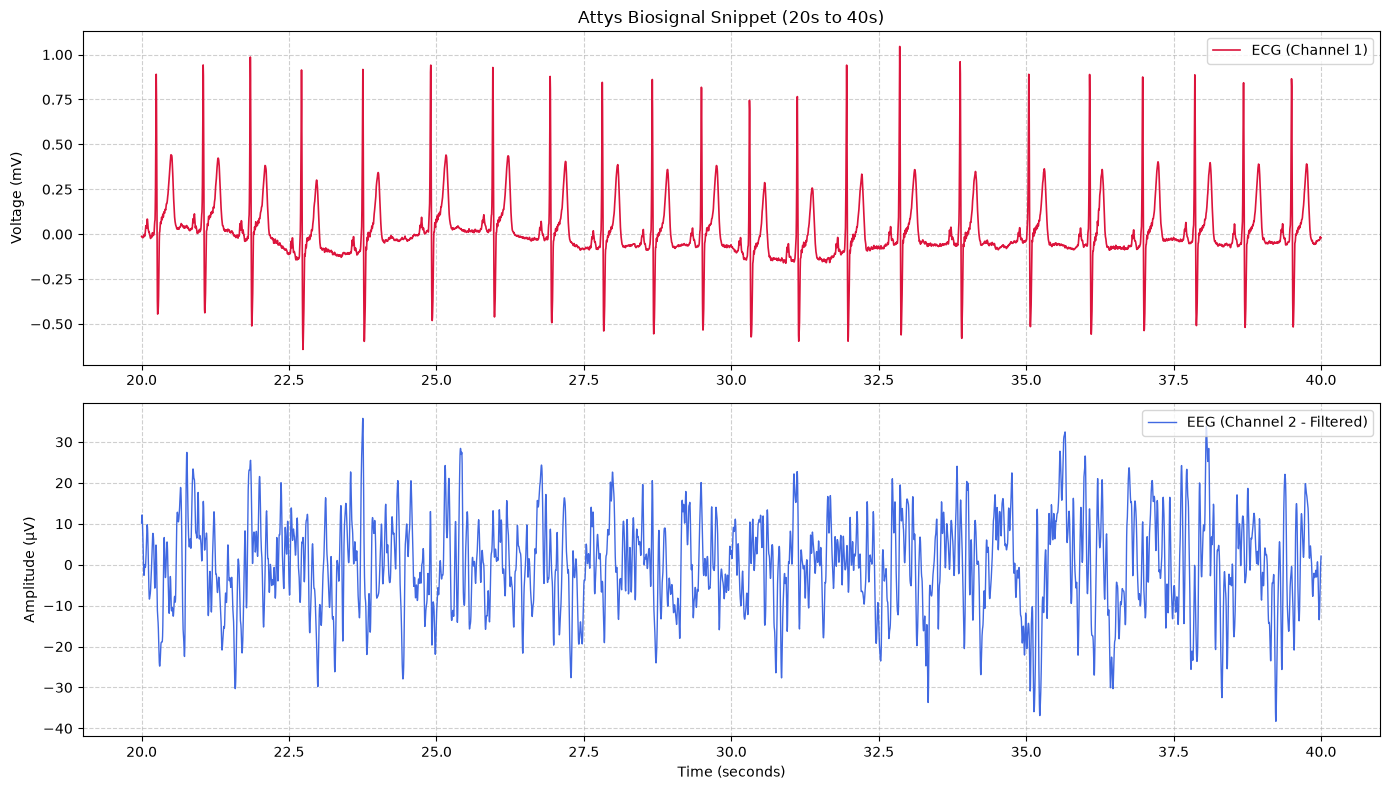

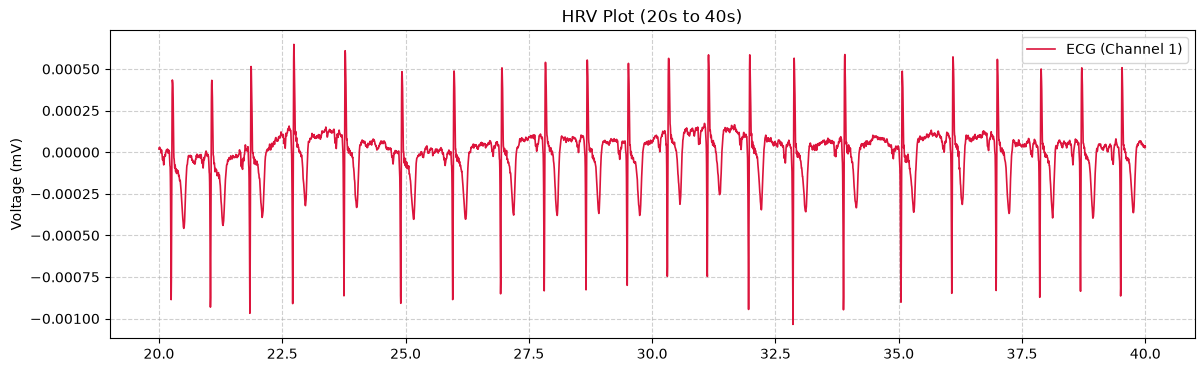

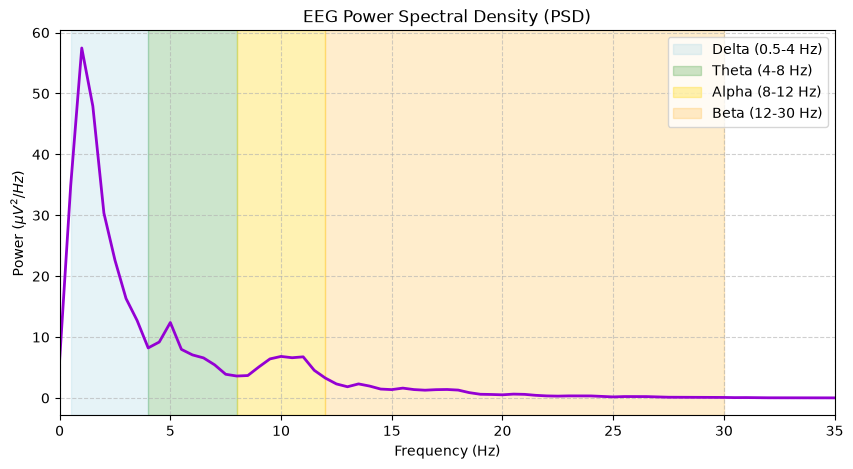

[]

In [64]:
plot_mask = (time >= t_start) & (time <= t_end)
time_plot = time[plot_mask]
ecg_plot = ecg_mv[plot_mask]
eeg_plot = eeg_filtered[plot_mask]
HRV_plot = HRV[plot_mask]

# Plotting both EEG and ECG
fig_ecg_eeg = plt.figure(figsize=(14, 8))

# Subplot 1: ECG (Channel 1)
plt.subplot(2, 1, 1)
plt.plot(time_plot, ecg_plot, color='crimson', linewidth=1.2, label='ECG (Channel 1)')
plt.ylabel('Voltage (mV)')
plt.title(f'Attys Biosignal Snippet ({t_start}s to {t_end}s)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

# Subplot 2: EEG (Channel 2)
plt.subplot(2, 1, 2)
plt.plot(time_plot, eeg_plot, color='royalblue', linewidth=1.0, label='EEG (Channel 2 - Filtered)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (µV)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


# Welch's Power Spectral Density (PSD)


fig_psd = plt.figure(figsize=(10, 5))
plt.plot(freqs, psd, color='darkviolet', linewidth=2)
plt.xlim(0, 35)  # Focus on 0 to 35 Hz
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power ($\mu V^2 / Hz$)')
plt.title('EEG Power Spectral Density (PSD)')
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight Standard EEG Bands 

plt.axvspan(0.5, 4, color='lightblue', alpha=0.3, label='Delta (0.5-4 Hz)')
plt.axvspan(4, 8, color='green', alpha=0.2, label='Theta (4-8 Hz)')
plt.axvspan(8, 12, color='gold', alpha=0.3, label='Alpha (8-12 Hz)')
plt.axvspan(12, 30, color='orange', alpha=0.2, label='Beta (12-30 Hz)')

plt.legend(loc='upper right')
plt.show()
plt.get_fignums()

In [54]:
## Saving data

fig_ecg_eeg.savefig(os.path.join(save_folder, "ECG_EEG.png"),
                    dpi=300, bbox_inches='tight')

fig_psd.savefig(os.path.join(save_folder, "PSD.png"),
                dpi=300, bbox_inches='tight')